In [ ]:
Caculate RFF Feature Based on the Sampling Preamble

In [7]:
import os
import math
import ast
import re
from pathlib import Path
import numpy as np
import pandas as pd

# ----------------------- Utility Functions -----------------------------

def distance(a: float, b: float, c: float, d: float) -> float:
    """Euclidean distance between (a,b) and (c,d)."""
    return math.hypot(a - c, d - b)

def power(x: np.ndarray) -> float:
    """Sum of squares."""
    x = np.asarray(x, dtype=float)
    return float(np.sum(x * x))

def frac_dimension(sample_real: np.ndarray, sample_imag: np.ndarray, tau: int) -> float:
    """Fractal dimension estimator (same formula as MATLAB version)."""
    N = len(sample_real)
    if N < 2 or tau < 2:
        return float("nan")

    # sum over step = 1 (adjacent samples)
    m1_end = N - (N % tau) - 2
    if m1_end < 0:
        return float("nan")
    summary_1 = 0.0
    for i in range(0, m1_end + 1):
        summary_1 += distance(sample_real[i], sample_imag[i],
                              sample_real[i + 1], sample_imag[i + 1])

    # sum over step = tau
    m_tau_end = (N - (N % tau)) // tau - 2
    if m_tau_end < 0:
        return float("nan")
    summary_tau = 0.0
    for i in range(0, m_tau_end + 1):
        summary_tau += distance(sample_real[i * tau], sample_imag[i * tau],
                                sample_real[(i + 1) * tau], sample_imag[(i + 1) * tau])

    if summary_1 <= 0 or summary_tau <= 0:
        return float("nan")

    dim = 0.5 * (3.0 - ((math.log10(summary_tau) - math.log10(summary_1)) / math.log10(tau)))
    return dim

def parse_complex_list(cell) -> np.ndarray:

    if pd.isna(cell):
        return np.array([], dtype=complex)

    s = str(cell)
    # 去掉所有空白字符（包含空格/换行/制表符）
    s = re.sub(r'\s+', '', s)
    # 统一虚数符号
    s = s.replace('i', 'j')

    # 确保外层有方括号，便于后续处理
    if not (s.startswith('[') and s.endswith(']')):
        s = f'[{s}]'

    # 用正则抓取形如 a±bj 的每个复数，a/b 都可带小数或科学计数法
    patt = re.compile(
        r'[+-]?'
        r'(?:\d+(?:\.\d+)?(?:e[+-]?\d+)?)'   # 实部
        r'[+-]'
        r'(?:\d+(?:\.\d+)?(?:e[+-]?\d+)?)j', # 虚部（带 j）
        re.IGNORECASE
    )
    parts = patt.findall(s)
    if parts:
        try:
            return np.array([complex(p) for p in parts], dtype=complex)
        except Exception:
            pass  # 回退到字面量解析

    # 回退：字面量解析（若原串本身就是标准 Python 列表）
    try:
        lst = ast.literal_eval(s)
        return np.array(lst, dtype=complex)
    except Exception:
        return np.array([], dtype=complex)  # 彻底失败则返回空

def fmt_complex_list(arr: np.ndarray) -> str:
    """
    输出与 MATLAB 生成的风格一致的字符串：不带括号的 a+bj / a-bj，列表用方括号包裹。
    """
    out = []
    for z in np.asarray(arr, dtype=complex).tolist():
        a = z.real
        b = z.imag
        if abs(a) < 1e-12: a = 0.0
        if abs(b) < 1e-12: b = 0.0
        sign = '+' if b >= 0 else ''
        out.append(f"{a:g}{sign}{b:g}j")
    return '[' + ', '.join(out) + ']'

# ---------------------- Main Processing -------------------------------

def main():
    # 参数
    N_target = 1000      # 每个文件处理前 N 行
    tau = 3              # fractal dimension 参数

    # 路径
    try:
        script_dir = Path(__file__).resolve().parent
    except NameError:
        # 在交互式/Notebook 下没有 __file__
        script_dir = Path(os.getcwd()).resolve()

    targetFolderName = '/Users/gzw/RFF_Data/Original_Data'
    storeFolderName  = '/Users/gzw/RFF_Data/RFF_DataSet'

    src_dir = script_dir / targetFolderName
    dst_dir = script_dir / storeFolderName
    dst_dir.mkdir(parents=True, exist_ok=True)

    # 列出文件（去除隐藏文件）
    all_files = sorted([p for p in src_dir.iterdir() if p.is_file() and not p.name.startswith('.')])
    error_files = []
    ok_files = []

    # 只处理前 123 个（与 MATLAB for file_index=1:123 对齐）
    max_count = min(123, len(all_files))
    for file_idx in range(max_count):
        src_path = all_files[file_idx]
        dst_path = dst_dir / src_path.name

        try:
            df = pd.read_csv(src_path)
        except Exception as e:
            print(f"[READ-ERR] {src_path.name}: {e}")
            error_files.append(src_path.name)
            continue

        columnName = 'preamble'
        if columnName not in df.columns:
            print(f'Column "{columnName}" does not exist in CSV file: {src_path.name}')
            error_files.append(src_path.name)
            continue

        # 预分配（与 MATLAB 中 height(dataTable) 对齐）
        H = len(df)
        iq_preamble_col = [None] * H
        frac_dim_1_col  = [None] * H
        frac_dim_2_col  = [None] * H
        iqi_1_col       = [None] * H
        iqi_2_col       = [None] * H

        mag_err_1_mean_col = [None] * H
        mag_err_2_mean_col = [None] * H
        phs_err_1_mean_col = [None] * H
        phs_err_2_mean_col = [None] * H

        mag_err_1_var_col  = [None] * H
        mag_err_2_var_col  = [None] * H
        phs_err_1_var_col  = [None] * H
        phs_err_2_var_col  = [None] * H

        mag_err_1_vec_col  = [None] * H
        mag_err_2_vec_col  = [None] * H
        phs_err_1_vec_col  = [None] * H
        phs_err_2_vec_col  = [None] * H

        short_freq_col = [None] * H
        long_freq_col  = [None] * H
        CFO_col        = [None] * H

        # 已知频域序列（64 点）
        L_long = np.array([
            0,0,0,0,0,0,1,1,-1,-1,1,1,-1,1,-1,1,1,1,1,1,1,-1,-1,1,1,-1,1,-1,1,1,1,1,
            0,1,-1,-1,1,1,-1,1,-1,1,-1,-1,-1,-1,-1,1,1,-1,-1,1,-1,1,-1,1,1,1,1,0,0,0,0,0
        ], dtype=float)

        samples_raw = df[columnName].values
        N = min(len(samples_raw), N_target)

        for idx in range(N):
            complexData = parse_complex_list(samples_raw[idx])
            if complexData.size < 288:
                continue

            # 取 128 + 32 + 128
            S_short = complexData[0:128]     # 8 short preambles (128 samples)
            # S_space = complexData[128:160] # 保护间隔（未用）
            S_long  = complexData[160:288]   # long preamble (128 samples)

            # -------- CFO 估计：短训练序列 --------
            a_ST_s_sum = 0+0j
            for i in range(0, 112):  # 0..111
                a_ST_s_sum += np.conj(S_short[i]) * S_short[i + 16]
            a_ST_s = (1.0/16.0) * np.angle(a_ST_s_sum)

            # -------- 第一次 CFO 校正（长训练）--------
            m = np.arange(len(S_long))
            corrected_1 = S_long * np.exp(-1j * m * a_ST_s)

            # -------- 根据一次校正后的长序列再估计 CFO --------
            a_ST_L_sum = 0+0j
            for i in range(0, 64):
                a_ST_L_sum += np.conj(corrected_1[i]) * corrected_1[i + 64]
            a_ST_L = (1.0/64.0) * np.angle(a_ST_L_sum)

            # -------- 第二次校正 --------
            corrected_2 = corrected_1 * np.exp(-1j * m * a_ST_L)

            # ---------------- 频域均衡 ----------------
            long1 = corrected_2[0:64]
            long2 = corrected_2[64:128]

            k1 = np.fft.fftshift(np.fft.fft(long1))
            k2 = np.fft.fftshift(np.fft.fft(long2))

            H_est = (0.5 * (k1 + k2)) / L_long

            X1 = np.fft.fftshift(np.fft.fft(long1))
            X2 = np.fft.fftshift(np.fft.fft(long2))

            # 零除保护
            #H_safe = np.where(np.abs(H_est) < 1e-12, 1e-12, H_est)
            Y1 = X1 / H_est
            Y2 = X2 / H_est

            mask1 = np.isnan(Y1.real) | np.isnan(Y1.imag)
            mask2 = np.isnan(Y2.real) | np.isnan(Y2.imag)
            Y1[mask1] = 0
            Y2[mask2] = 0
            #Y1 = np.where(Y1 == None, 0, Y1)
            #Y2 = np.where(Y2 == None, 0, Y2)

            # 去掉已知导频符号（误差向量）
            Y1 = Y1 - L_long
            Y2 = Y2 - L_long

            # 误差向量
            mag_err_1 = np.abs(L_long) - np.abs(Y1)
            mag_err_2 = np.abs(L_long) - np.abs(Y2)
            phs_err_1 = np.angle(L_long) - np.angle(Y1)
            phs_err_2 = np.angle(L_long) - np.angle(Y2)

            # 统计量
            mag_err_1_mean = float(np.mean(mag_err_1))
            mag_err_2_mean = float(np.mean(mag_err_2))
            phs_err_1_mean = float(np.mean(phs_err_1))
            phs_err_2_mean = float(np.mean(phs_err_2))

            mag_err_1_var  = float(np.var(mag_err_1))
            mag_err_2_var  = float(np.var(mag_err_2))
            phs_err_1_var  = float(np.var(phs_err_1))
            phs_err_2_var  = float(np.var(phs_err_2))

            # 分形维度 & IQI
            iq_real_1, iq_imag_1 = np.real(Y1), np.imag(Y1)
            iq_real_2, iq_imag_2 = np.real(Y2), np.imag(Y2)

            Y1_frac = frac_dimension(iq_real_1, iq_imag_1, tau)
            Y2_frac = frac_dimension(iq_real_2, iq_imag_2, tau)

            iqi_1 = power(iq_real_1) / max(power(iq_imag_1), 1e-12)
            iqi_2 = power(iq_real_2) / max(power(iq_imag_2), 1e-12)

            # 回填到列（字符串化存储）
            iq_preamble_col[idx] = fmt_complex_list(np.r_[Y1, Y2])
            frac_dim_1_col[idx]  = Y1_frac
            frac_dim_2_col[idx]  = Y2_frac
            iqi_1_col[idx]       = iqi_1
            iqi_2_col[idx]       = iqi_2

            mag_err_1_mean_col[idx] = mag_err_1_mean
            mag_err_2_mean_col[idx] = mag_err_2_mean
            phs_err_1_mean_col[idx] = phs_err_1_mean
            phs_err_2_mean_col[idx] = phs_err_2_mean

            mag_err_1_var_col[idx]  = mag_err_1_var
            mag_err_2_var_col[idx]  = mag_err_2_var
            phs_err_1_var_col[idx]  = phs_err_1_var
            phs_err_2_var_col[idx]  = phs_err_2_var

            mag_err_1_vec_col[idx]  = '[' + ', '.join(f'{v:g}' for v in mag_err_1.tolist()) + ']'
            mag_err_2_vec_col[idx]  = '[' + ', '.join(f'{v:g}' for v in mag_err_2.tolist()) + ']'
            phs_err_1_vec_col[idx]  = '[' + ', '.join(f'{v:g}' for v in phs_err_1.tolist()) + ']'
            phs_err_2_vec_col[idx]  = '[' + ', '.join(f'{v:g}' for v in phs_err_2.tolist()) + ']'

            short_freq_col[idx] = a_ST_s
            long_freq_col[idx]  = a_ST_L
            CFO_col[idx]        = (a_ST_s + a_ST_L) * 20 * 1_000_000 / (2 * math.pi)

        # 清理旧列并写入新列
        for old_col in ('short_freq', 'long_freq', 'frequencyOffset', 'frequencyoffset', 'freq_bench'):
            if old_col in df.columns:
                df.drop(columns=[old_col], inplace=True)

        df['iq_preamble']          = iq_preamble_col
        df['CFO']                  = CFO_col
        df['short_freq']           = short_freq_col
        df['long_freq']            = long_freq_col

        df['frac_dimension_1']     = frac_dim_1_col
        df['frac_dimension_2']     = frac_dim_2_col
        df['iqi_1']                = iqi_1_col
        df['iqi_2']                = iqi_2_col

        df['mag_error_vec_1']      = mag_err_1_vec_col
        df['mag_error_mean_1']     = mag_err_1_mean_col
        df['mag_error_var_1']      = mag_err_1_var_col

        df['mag_error_vec_2']      = mag_err_2_vec_col
        df['mag_error_mean_2']     = mag_err_2_mean_col
        df['mag_error_var_2']      = mag_err_2_var_col

        df['phase_error_vec_1']    = phs_err_1_vec_col
        df['phase_error_mean_1']   = phs_err_1_mean_col
        df['phase_error_var_1']    = phs_err_1_var_col

        df['phase_error_vec_2']    = phs_err_2_vec_col
        df['phase_error_mean_2']   = phs_err_2_mean_col
        df['phase_error_var_2']    = phs_err_2_var_col

        # 保存（UTF-8 编码）
        try:
            df.to_csv(dst_path, index=False, encoding='utf-8')
            ok_files.append(src_path.name)
        except Exception as e:
            print(f"[WRITE-ERR] {src_path.name}: {e}")
            error_files.append(src_path.name)

    print(f"[DONE] Saved {len(ok_files)} files to: {dst_dir}")
    if error_files:
        print(f"[WARN] Errors on {len(error_files)} files:")
        for n in error_files:
            print("  -", n)

if __name__ == "__main__":
    main()

/var/folders/gj/m224hrsx343bbt75r50p5zmr0000gn/T/ipykernel_1988/1174797613.py:218: RuntimeWarning: divide by zero encountered in divide
  H_est = (0.5 * (k1 + k2)) / L_long
/var/folders/gj/m224hrsx343bbt75r50p5zmr0000gn/T/ipykernel_1988/1174797613.py:225: RuntimeWarning: invalid value encountered in divide
  Y1 = X1 / H_est
/var/folders/gj/m224hrsx343bbt75r50p5zmr0000gn/T/ipykernel_1988/1174797613.py:226: RuntimeWarning: invalid value encountered in divide
  Y2 = X2 / H_est
/var/folders/gj/m224hrsx343bbt75r50p5zmr0000gn/T/ipykernel_1988/1174797613.py:218: RuntimeWarning: divide by zero encountered in divide
  H_est = (0.5 * (k1 + k2)) / L_long
/var/folders/gj/m224hrsx343bbt75r50p5zmr0000gn/T/ipykernel_1988/1174797613.py:225: RuntimeWarning: invalid value encountered in divide
  Y1 = X1 / H_est
/var/folders/gj/m224hrsx343bbt75r50p5zmr0000gn/T/ipykernel_1988/1174797613.py:226: RuntimeWarning: invalid value encountered in divide
  Y2 = X2 / H_est
/var/folders/gj/m224hrsx343bbt75r50p5zmr00

[DONE] Saved 123 files to: /Users/gzw/RFF_Data/RFF_DataSet


In [ ]:
Kalman Filtering

In [8]:
import os
import pandas as pd
import numpy as np
from pykalman import KalmanFilter

# 定义卡尔曼滤波函数
def apply_kalman_filter(df, columns):
    filtered_data = df.copy()
    for col in columns:
        if col in df.columns:
            try:
                # 处理 NaN 和 Inf
                col_data = df[col].replace([np.inf, -np.inf], np.nan)
                col_data = col_data.fillna(col_data.median())  # 用中位数填充
                
                # 初始化卡尔曼滤波器
                kf = KalmanFilter(initial_state_mean=0, n_dim_obs=1)
                kf = kf.em(col_data.values, n_iter=10)
                
                # 应用卡尔曼滤波
                filtered_col, _ = kf.filter(col_data.values)
                filtered_data[col] = filtered_col
            except Exception as e:
                print(f"Skipping column {col} due to error: {e}")
    return filtered_data

# 遍历文件夹并处理所有 CSV 文件
def process_csv_files(input_folder, output_folder, filter_columns):
    for root, _, files in os.walk(input_folder):
        for file in files:
            if file.endswith('.csv'):
                file_path = os.path.join(root, file)
                print(f"Processing file: {file_path}")
                
                # 读取 CSV 文件
                df = pd.read_csv(file_path)
                
                # 检查需要处理的列是否存在
                cols_to_filter = [col for col in filter_columns if col in df.columns]
                if not cols_to_filter:
                    print(f"No specified columns to process in {file_path}")
                    continue
                
                # 对指定列进行滤波
                filtered_df = apply_kalman_filter(df, cols_to_filter)
                
                # 确定输出路径，保持子目录结构
                relative_path = os.path.relpath(file_path, input_folder)
                output_path = os.path.join(output_folder, relative_path)
                output_dir = os.path.dirname(output_path)
                
                # 确保输出目录存在
                if not os.path.exists(output_dir):
                    os.makedirs(output_dir)
                
                # 保存处理后的文件
                filtered_df.to_csv(output_path, index=False)
                print(f"Saved filtered file to: {output_path}")

# 定义输入文件夹和输出文件夹路径
input_folders = [
    "/Users/gzw/RFF_Data/RFF_DataSet"
]
output_folder = "/Users/gzw/RFF_Data/RFF_DataSet_KF"

# 需要进行滤波的列
filter_columns = ["CFO", "short_freq", "long_freq", "frac_dimension_1", "frac_dimension_2", "iqi_1", "iqi_2",  "mag_error_mean_1", "mag_error_var_1",  "mag_error_mean_2", "mag_error_var_2",  "phase_error_mean_1", "phase_error_var_1",  "phase_error_mean_2", "phase_error_var_2"]


# 处理所有文件夹
for folder in input_folders:
    process_csv_files(folder, output_folder, filter_columns)


Processing file: /Users/gzw/RFF_Data/RFF_DataSet/78_21_84_93_57_80_pre.csv
Saved filtered file to: /Users/gzw/RFF_Data/RFF_DataSet_KF/78_21_84_93_57_80_pre.csv
Processing file: /Users/gzw/RFF_Data/RFF_DataSet/78_21_84_93_56_00_pre.csv
Saved filtered file to: /Users/gzw/RFF_Data/RFF_DataSet_KF/78_21_84_93_56_00_pre.csv
Processing file: /Users/gzw/RFF_Data/RFF_DataSet/78_21_84_93_56_10_pre.csv
Saved filtered file to: /Users/gzw/RFF_Data/RFF_DataSet_KF/78_21_84_93_56_10_pre.csv
Processing file: /Users/gzw/RFF_Data/RFF_DataSet/24_d7_eb_38_e3_1c_pre.csv
Saved filtered file to: /Users/gzw/RFF_Data/RFF_DataSet_KF/24_d7_eb_38_e3_1c_pre.csv
Processing file: /Users/gzw/RFF_Data/RFF_DataSet/24_d7_eb_38_ef_28_pre.csv
Saved filtered file to: /Users/gzw/RFF_Data/RFF_DataSet_KF/24_d7_eb_38_ef_28_pre.csv
Processing file: /Users/gzw/RFF_Data/RFF_DataSet/78_21_84_93_55_fc_pre.csv
Saved filtered file to: /Users/gzw/RFF_Data/RFF_DataSet_KF/78_21_84_93_55_fc_pre.csv
Processing file: /Users/gzw/RFF_Data/RFF

In [ ]:
tSNE

[120  90  11  76  52 118  85  12  25 103]


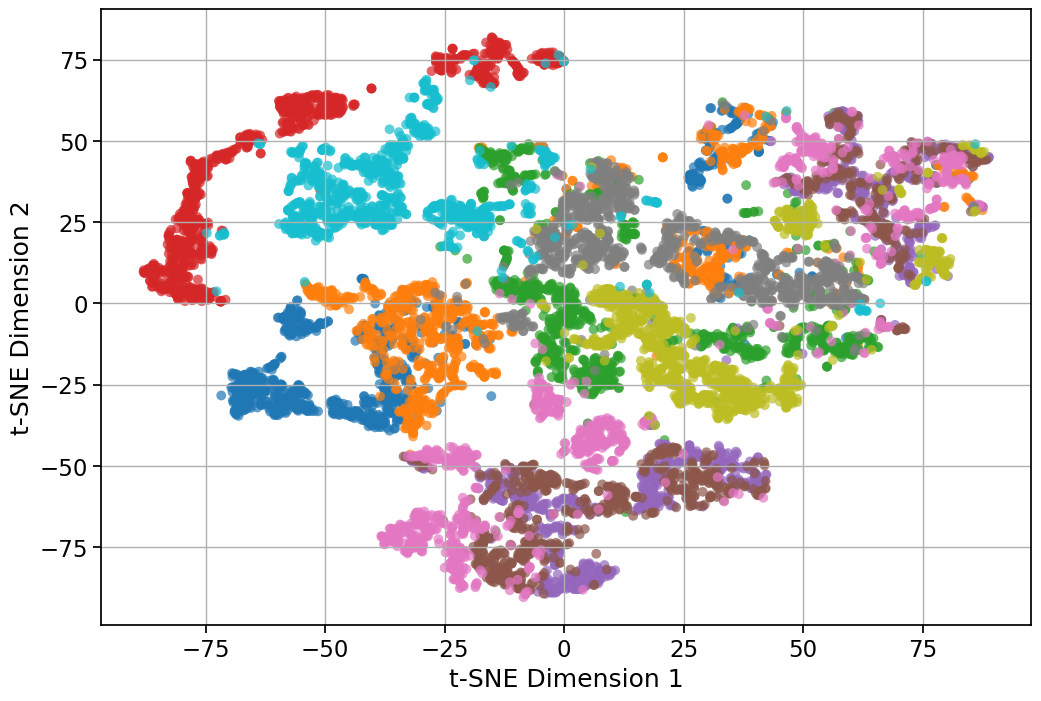

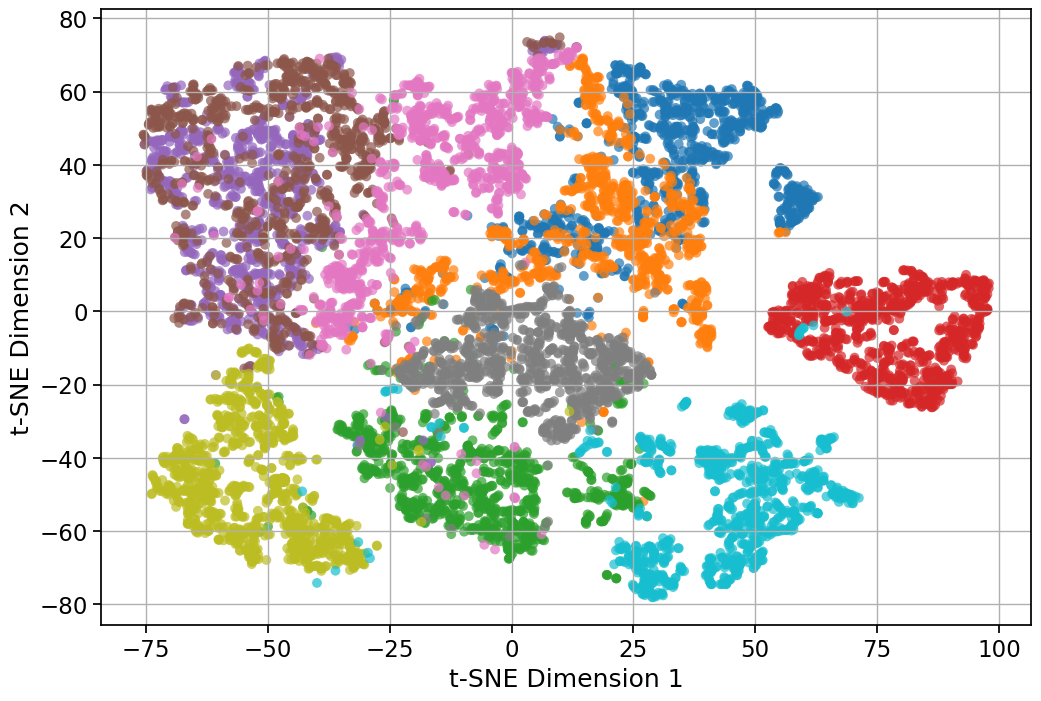

In [14]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.manifold import TSNE
import seaborn as sns

plt.rcParams.update({'font.size': 12})
sns.set_context("notebook", font_scale=1.5)

# 数据路径
original_data_path = '/Users/gzw/RFF_Data/RFF_DataSet'
KF_data_path = '/Users/gzw/RFF_Data/RFF_DataSet_KF'


# 特征列表

features = ["CFO", "short_freq", "long_freq","frac_dimension_1", "frac_dimension_2", "iqi_1", "iqi_2",  "mag_error_mean_1", "mag_error_var_1",  "mag_error_mean_2", "mag_error_var_2",  "phase_error_mean_1", "phase_error_var_1",  "phase_error_mean_2", "phase_error_var_2"]


# 初始化模型和编码器
scaler = StandardScaler()
label_encoder = LabelEncoder()

def load_and_preprocess_data(folder_path, label_offset=0):
    """
    从指定文件夹加载CSV数据并预处理
    """
    files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]
    combined_data = pd.DataFrame()
    
    for file in files:
        file_path = os.path.join(folder_path, file)
        data = pd.read_csv(file_path)
        combined_data = pd.concat([combined_data, data], ignore_index=True)
    
    # 处理缺失值
    combined_data = combined_data.dropna(subset=features)
    
    # 处理MAC地址
    if 'MAC_address' in combined_data.columns:
        combined_data['MAC_label'] = label_encoder.fit_transform(combined_data['MAC_address']) + label_offset

    return combined_data

# 读取数据
known_data = load_and_preprocess_data(original_data_path)
known_data_kf = load_and_preprocess_data(KF_data_path)

# 人工抽取设备编号
rng = np.random.default_rng(seed=42)  # 建立随机数生成器<br/>
fixed_devices = rng.choice(np.arange(1, 124), size=10, replace=False)
print(fixed_devices)

#fixed_devices = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

# 筛选出对应设备的样本
selected_data = known_data[known_data['MAC_label'].isin(fixed_devices)]
selected_features = selected_data[features]
selected_labels = selected_data['MAC_label']

selected_data_kf = known_data_kf[known_data_kf['MAC_label'].isin(fixed_devices)]
selected_features_kf = selected_data_kf[features]
selected_labels_kf = selected_data_kf['MAC_label']

# 标准化数据
selected_features_scaled = scaler.fit_transform(selected_features)

selected_features_scaled_kf = scaler.fit_transform(selected_features_kf)



# t-SNE 降维
tsne_2d = TSNE(n_components=2, perplexity=30, random_state=42)
selected_tsne_2d = tsne_2d.fit_transform(selected_features_scaled)

selected_tsne_2d_kf = tsne_2d.fit_transform(selected_features_scaled_kf)



# 颜色映射
palette = sns.color_palette("tab10", len(fixed_devices))  
device_color_map = {device: palette[idx] for idx, device in enumerate(fixed_devices)}

# t-SNE 2D 可视化
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x=selected_tsne_2d[:, 0], y=selected_tsne_2d[:, 1],
    hue=selected_labels.map(device_color_map), palette=palette, s=50, alpha=0.7, edgecolor='none'
)
#plt.title("t-SNE 2D Visualization (Fixed Devices)")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
#plt.legend(title="Device", loc="best", bbox_to_anchor=(1.05, 1))
plt.legend().set_visible(False)
plt.grid()
plt.savefig("tSNE.pdf",bbox_inches="tight")
plt.show()

# t-SNE 2D 可视化 kf
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x=selected_tsne_2d_kf[:, 0], y=selected_tsne_2d_kf[:, 1],
    hue=selected_labels_kf.map(device_color_map), palette=palette, s=50, alpha=0.7, edgecolor='none'
)
#plt.title("t-SNE 2D Visualization (Fixed Devices)")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
#plt.legend(title="Device", loc="best", bbox_to_anchor=(1.05, 1))
plt.legend().set_visible(False)
plt.grid()
plt.savefig("tSNE_KF.pdf",bbox_inches="tight")
plt.show()


In [ ]:
Random Forest

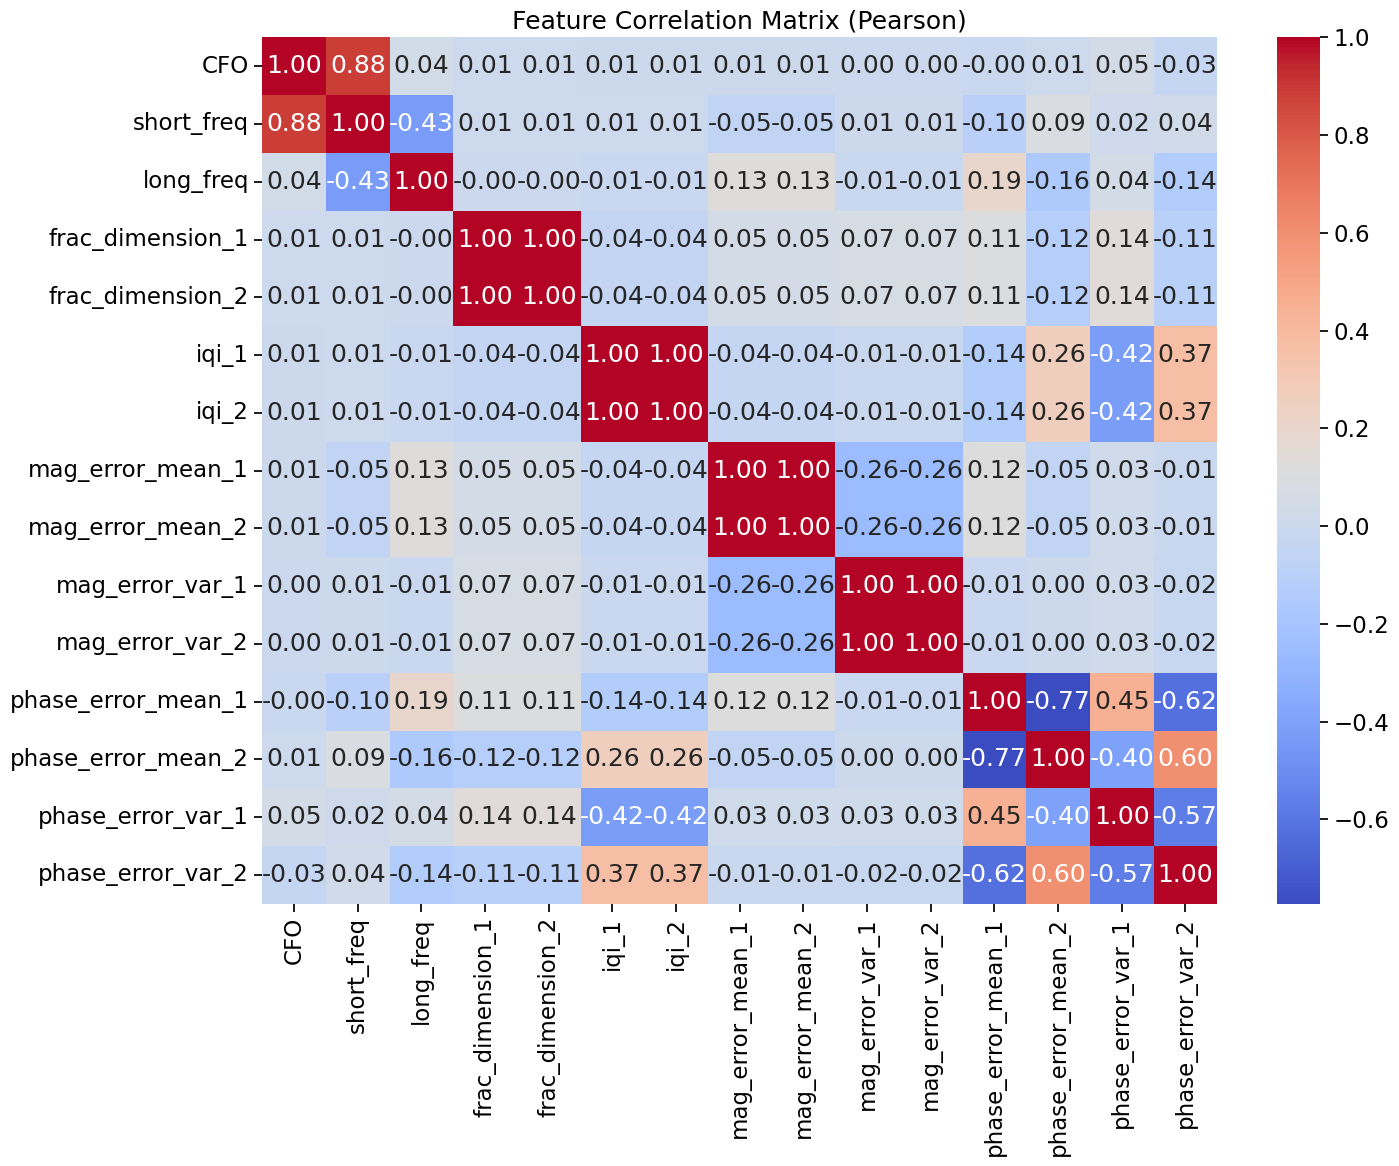


=== Feature Importance Ranking ===
CFO                             Importance: 0.179215
short_freq                      Importance: 0.165812
long_freq                       Importance: 0.129601
phase_error_mean_1              Importance: 0.070081
phase_error_mean_2              Importance: 0.061885
phase_error_var_1               Importance: 0.050089
mag_error_mean_2                Importance: 0.044502
mag_error_mean_1                Importance: 0.043666
phase_error_var_2               Importance: 0.040298
mag_error_var_2                 Importance: 0.040238
iqi_1                           Importance: 0.040118
mag_error_var_1                 Importance: 0.040046
iqi_2                           Importance: 0.040010
frac_dimension_2                Importance: 0.027229
frac_dimension_1                Importance: 0.027209

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.72      0.75       204
           1       0.98      0.96   

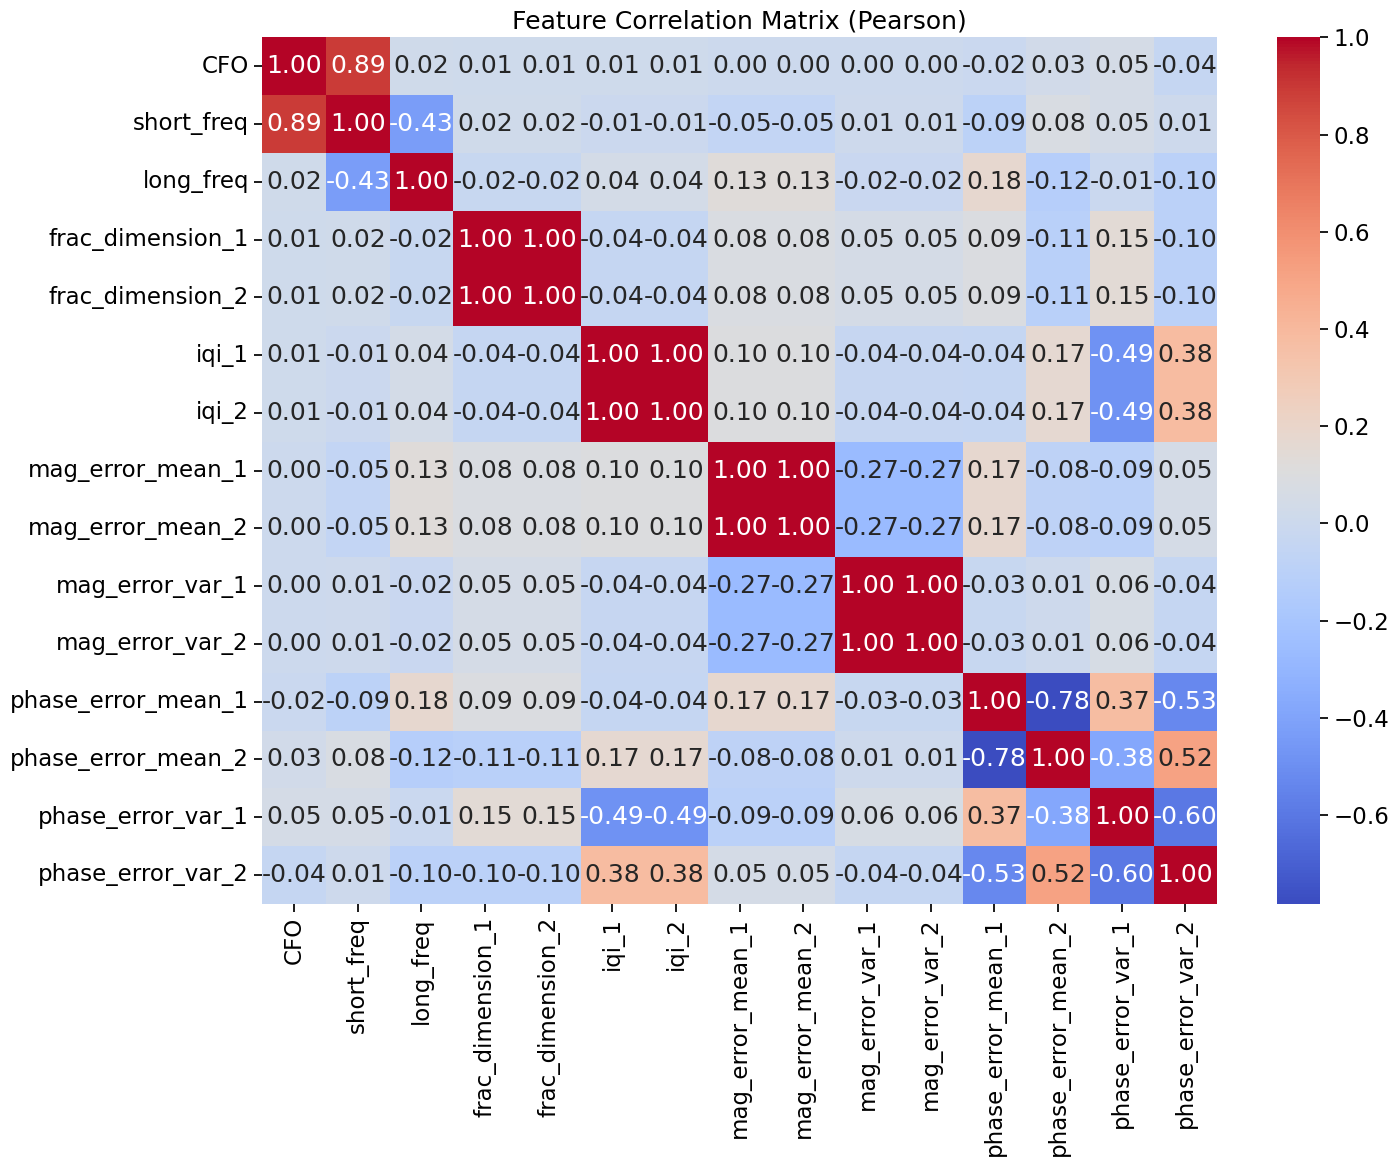


=== Feature Importance Ranking ===
CFO                             Importance: 0.219931
short_freq                      Importance: 0.176022
long_freq                       Importance: 0.144291
phase_error_mean_1              Importance: 0.056188
phase_error_mean_2              Importance: 0.054382
phase_error_var_2               Importance: 0.041806
phase_error_var_1               Importance: 0.041734
iqi_1                           Importance: 0.038231
mag_error_mean_2                Importance: 0.038063
mag_error_mean_1                Importance: 0.037530
iqi_2                           Importance: 0.037478
mag_error_var_1                 Importance: 0.030544
mag_error_var_2                 Importance: 0.030530
frac_dimension_1                Importance: 0.026785
frac_dimension_2                Importance: 0.026485

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.78      0.80       202
           1       0.97      0.99   

In [12]:
import os
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({'font.size': 12})
sns.set_context("notebook", font_scale=1.5)

# 配置路径



# 加载数据函数
def load_data(folder_path, features, label_column='MAC_address'):
    files = [f for f in os.listdir(folder_path) if f.endswith('.csv')]
    combined_data = pd.DataFrame()
    for file in files:
        file_path = os.path.join(folder_path, file)
        data = pd.read_csv(file_path)
        combined_data = pd.concat([combined_data, data], ignore_index=True)
    combined_data = combined_data.dropna(subset=features)
    return combined_data



# 计算特征相关性矩阵（使用 Pearson 相关系数）
def plot_correlation_matrix(data, features, title="Feature Correlation Matrix (Pearson)"):
    correlation_matrix = data[features].corr(method='pearson')  # 使用 Pearson 相关系数
    plt.figure(figsize=(15, 12))
    sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
    plt.title(title)
    plt.tight_layout()
    plt.savefig("correlation_matrix.pdf",bbox_inches='tight')
    plt.show()


# 基于随机森林的特征重要性分析
def print_feature_importance(model, feature_names):
    """
    输出按重要性排序的特征名称及其重要程度。
    """
    importance = model.feature_importances_
    sorted_indices = np.argsort(importance)[::-1]  # 降序排序

    print("\n=== Feature Importance Ranking ===")
    for i in sorted_indices:
        print(f"{feature_names[i]:<30s}  Importance: {importance[i]:.6f}")

    # 如果想以DataFrame形式返回，也可以这样
    importance_df = (
        pd.DataFrame({
            "Feature": np.array(feature_names)[sorted_indices],
            "Importance": importance[sorted_indices]
        })
        .reset_index(drop=True)
    )

    return importance_df



# 随机森林分类测试评估
def evaluate_model(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    print("\nClassification Report:")
    print(classification_report(y_eval, y_pred))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_eval, y_pred))
    print("\nAccuracy Score:")
    print(f"{accuracy_score(y_eval, y_pred):.4f}")


def Random_Forest(data_path, features):
    # 加载训练数据
    known_data = load_data(data_path, features)

    # 标签编码
    label_encoder = LabelEncoder()
    known_data['MAC_label'] = label_encoder.fit_transform(known_data['MAC_address'])

    # 分离特征和标签
    X_known = known_data[features]
    y_known = known_data['MAC_label']

    # 标准化特征
    scaler = StandardScaler()
    X_known_scaled = scaler.fit_transform(X_known)

    # 划分训练和评估集
    X_train, X_eval, y_train, y_eval = train_test_split(X_known_scaled, y_known, test_size=0.2, random_state=42)

    # 训练随机森林模型
    rf_model = RandomForestClassifier(n_estimators=128, random_state=42)
    rf_model.fit(X_train, y_train)

    # 绘制特征相关性矩阵
    plot_correlation_matrix(known_data, features, title="Feature Correlation Matrix (Pearson)")
    # 绘制特征重要性
    print_feature_importance(rf_model, features)
    # 评估模型性能
    evaluate_model(rf_model, X_eval, y_eval)

if __name__ == "__main__":
    original_data_path = '/Users/gzw/RFF_Data/RFF_DataSet'
    KF_data_path = '/Users/gzw/RFF_Data/RFF_DataSet_KF'

    # 特征选择
    features = ["CFO", "short_freq", "long_freq", "frac_dimension_1", "frac_dimension_2", "iqi_1", "iqi_2",
                "mag_error_mean_1", "mag_error_mean_2", "mag_error_var_1", "mag_error_var_2", "phase_error_mean_1",
                "phase_error_mean_2", "phase_error_var_1", "phase_error_var_2"]
    Random_Forest(original_data_path, features)
    Random_Forest(KF_data_path, features)